### EDA do experimento `collection_v2` (MLflow)

Baseline de cada arquitetura contra a melhor variante da grade de treinos
(split 70/15/15, `input_window=24`).

In [1]:
from pathlib import Path

import mlflow
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

MLFLOW_DB = Path("../training/mlflow.db")
EXPERIMENT_NAME = "mimo_sys_collection_v2"

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

/home/rwp/code/mimo_sys/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Runs do experimento

Um run por `(modelo, variante)` — `<modelo>` é o baseline, `<modelo>_otimizado` é a melhor variante da grade.

In [2]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
runs = runs.rename(columns={"tags.mlflow.runName": "run"}).set_index("run")
runs["modelo"] = runs.index.str.removesuffix("_otimizado")
runs["variante"] = runs.index.to_series().apply(
    lambda r: "otimizado" if r.endswith("_otimizado") else "baseline"
)

print(f"{len(runs)} runs em '{EXPERIMENT_NAME}'")
runs[["modelo", "variante", "status", "start_time"]]

8 runs em 'mimo_sys_collection_v2'


,modelo,variante,status,start_time
run,,,,
seq2seq_latent_gnn_otimizado,seq2seq_latent_gnn,otimizado,FINISHED,2026-10-15 21:24:58.839000+00:00
seq2seq_latent_gnn,seq2seq_latent_gnn,baseline,FINISHED,2026-10-15 21:23:06.717000+00:00
stemgnn_otimizado,stemgnn,otimizado,FINISHED,2026-10-15 21:22:06.004000+00:00
stemgnn,stemgnn,baseline,FINISHED,2026-10-15 21:20:59.228000+00:00
sgn_otimizado,sgn,otimizado,FINISHED,2026-10-15 21:20:30.075000+00:00
sgn,sgn,baseline,FINISHED,2026-10-15 21:20:08.254000+00:00
mpnn_otimizado,mpnn,otimizado,FINISHED,2026-10-15 21:19:36.573000+00:00
mpnn,mpnn,baseline,FINISHED,2026-10-15 21:19:19.242000+00:00


### Métricas por saída (teste, forecast encadeado, escala original)

In [3]:
OUTPUT_COLS = ["vazao_distribuicao", "nivel_res", "pressao"]


def metric_table(metric: str) -> pd.DataFrame:
    """Uma coluna por saída para `metric` (ex.: 'r2', 'smape_pct')."""
    key = "smape_pct" if metric == "smape_pct" else metric
    cols = {out: f"metrics.chained_{key}_{out}" for out in OUTPUT_COLS}
    table = runs[list(cols.values())].rename(
        columns={v: k for k, v in cols.items()}
    )
    table.insert(0, "variante", runs["variante"])
    table.insert(0, "modelo", runs["modelo"])
    return table


r2 = metric_table("r2")
r2.round(3).sort_values(["modelo", "variante"])

,modelo,variante,vazao_distribuicao,nivel_res,pressao
run,,,,,
mpnn,mpnn,baseline,0.909,0.371,0.667
mpnn_otimizado,mpnn,otimizado,0.902,0.433,0.665
seq2seq_latent_gnn,seq2seq_latent_gnn,baseline,0.881,0.325,0.648
seq2seq_latent_gnn_otimizado,seq2seq_latent_gnn,otimizado,0.895,0.387,0.692
sgn,sgn,baseline,0.917,0.273,0.699
sgn_otimizado,sgn,otimizado,0.913,0.282,0.690
stemgnn,stemgnn,baseline,0.895,0.376,0.610
stemgnn_otimizado,stemgnn,otimizado,0.901,0.399,0.618


In [4]:
smape = metric_table("smape_pct")
smape.round(2).sort_values(["modelo", "variante"])

,modelo,variante,vazao_distribuicao,nivel_res,pressao
run,,,,,
mpnn,mpnn,baseline,8.91,5.92,6.75
mpnn_otimizado,mpnn,otimizado,10.01,5.35,6.58
seq2seq_latent_gnn,seq2seq_latent_gnn,baseline,10.56,6.13,7.07
seq2seq_latent_gnn_otimizado,seq2seq_latent_gnn,otimizado,9.85,5.84,6.04
sgn,sgn,baseline,8.46,6.27,6.37
sgn_otimizado,sgn,otimizado,8.39,6.21,6.37
stemgnn,stemgnn,baseline,9.87,5.39,7.64
stemgnn_otimizado,stemgnn,otimizado,9.82,5.44,7.29


Ganho (otimizado − baseline) de R² médio por modelo.

In [5]:
r2_medio = r2[OUTPUT_COLS].mean(axis=1).rename("r2_medio")
ganho = r2_medio.groupby(runs["modelo"]).apply(
    lambda s: s.get(s.index[s.index.str.endswith("_otimizado")][0])
    - s.get(s.index[~s.index.str.endswith("_otimizado")][0])
)
ganho.round(3).sort_values(ascending=False)

modelo
seq2seq_latent_gnn    0.040
mpnn                  0.018
stemgnn               0.013
sgn                  -0.001
Name: r2_medio, dtype: float64

### Energia por banda espectral

Erro relativo de energia (%) nas bandas de `docs/5_eda-series-temporais.md` §7; mais perto de 0 é melhor.

In [6]:
BAND_ORDER = [
    "tendencia_acima_32h",
    "diario_16-32h",
    "harmonico_8-16h",
    "curto_4-8h",
    "ruido_2-4h",
]


def band_pivot(output: str) -> pd.DataFrame:
    """Modelo+variante × banda, erro relativo de energia (%)."""
    cols = {
        band: f"metrics.energia_rel_pct_{band}_{output}"
        for band in BAND_ORDER
    }
    cols = {k: v for k, v in cols.items() if v in runs.columns}
    return runs[list(cols.values())].rename(
        columns={v: k for k, v in cols.items()}
    )


band_pivot("vazao_distribuicao").round(1)

,tendencia_acima_32h,diario_16-32h,harmonico_8-16h,curto_4-8h,ruido_2-4h
run,,,,,
seq2seq_latent_gnn_otimizado,20.7,7.0,-23.4,-29.2,-28.1
seq2seq_latent_gnn,-63.6,-7.1,-45.2,-64.0,-64.3
stemgnn_otimizado,-62.5,-2.2,-27.4,-63.6,-65.7
stemgnn,-60.5,-9.0,-20.1,-62.4,-63.7
sgn_otimizado,-70.3,1.5,-34.3,-63.8,-75.0
sgn,-65.8,1.9,-32.1,-66.8,-76.6
mpnn_otimizado,-3.7,-0.4,-46.5,-44.1,-63.1
mpnn,-56.5,5.5,-45.5,-61.8,-70.7


In [7]:
band_pivot("nivel_res").round(1)

,tendencia_acima_32h,diario_16-32h,harmonico_8-16h,curto_4-8h,ruido_2-4h
run,,,,,
seq2seq_latent_gnn_otimizado,-27.0,51.3,-41.0,-29.5,25.2
seq2seq_latent_gnn,-59.2,43.9,-40.5,-38.8,224.8
stemgnn_otimizado,-50.4,23.4,-51.4,-51.7,104.6
stemgnn,-52.7,-1.8,-50.5,-57.9,88.5
sgn_otimizado,-82.1,7.6,-61.6,-58.1,85.4
sgn,-75.4,43.9,-64.4,-63.7,66.6
mpnn_otimizado,-71.4,29.9,-43.2,-39.6,117.4
mpnn,-68.6,5.0,-43.7,-44.7,177.3


In [8]:
band_pivot("pressao").round(1)

,tendencia_acima_32h,diario_16-32h,harmonico_8-16h,curto_4-8h,ruido_2-4h
run,,,,,
seq2seq_latent_gnn_otimizado,-51.8,22.9,-58.4,-58.5,-81.0
seq2seq_latent_gnn,-23.5,18.2,-65.6,-73.8,-90.6
stemgnn_otimizado,28.0,-9.4,-46.2,-74.3,-82.1
stemgnn,61.4,-12.1,-45.7,-73.3,-83.4
sgn_otimizado,-59.6,-13.9,-76.2,-81.1,-93.5
sgn,-56.5,-18.1,-60.3,-85.8,-94.1
mpnn_otimizado,-21.1,-13.2,-57.3,-75.5,-90.7
mpnn,-38.3,-9.6,-64.0,-79.1,-90.4


### Figuras (PNG) — medido vs. previsto e espectro

As figuras ficam como artefato — não vêm no `search_runs`. `show_artifact` baixa pelo `run_id`.

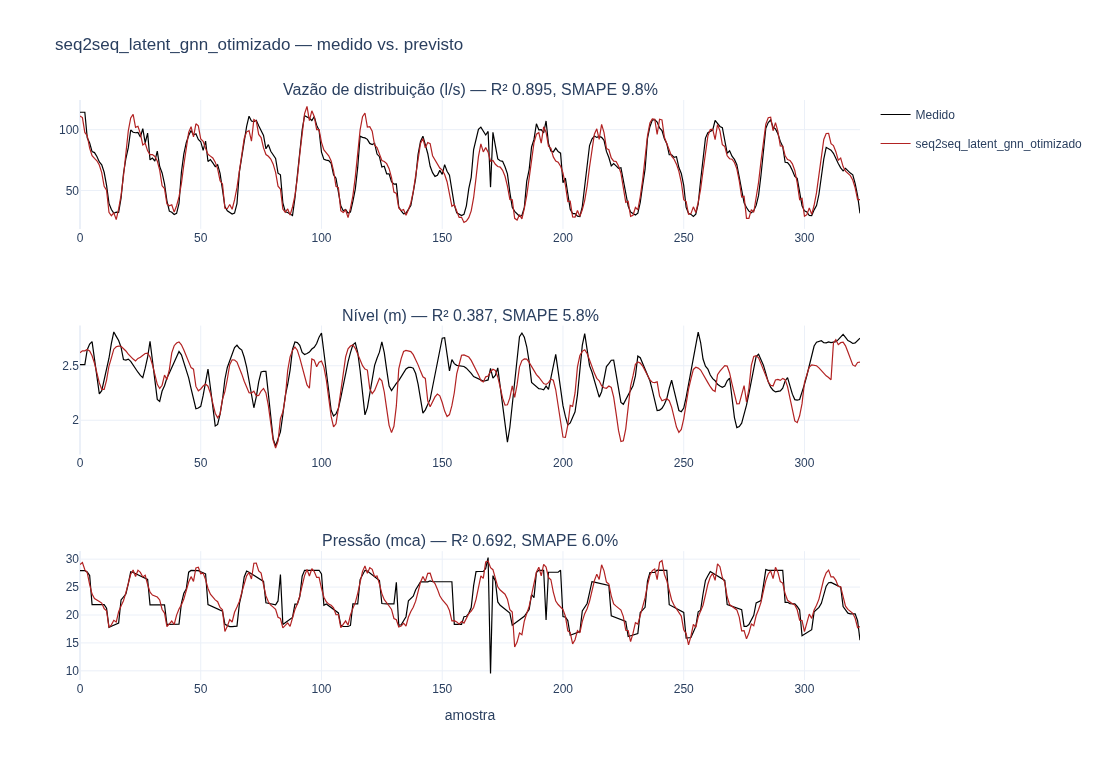

In [9]:
from IPython.display import Image
from mlflow.tracking import MlflowClient

client = MlflowClient()


def show_artifact(run_name: str, nome: str) -> Image:
    """Baixa e mostra um PNG de artefato do run `run_name`.

    `nome` é `'serie.png'` ou `'espectro.png'`.
    """
    run_id = runs.loc[run_name, "run_id"]
    local_path = client.download_artifacts(run_id, nome)
    return Image(local_path)


show_artifact("seq2seq_latent_gnn_otimizado", "serie.png")

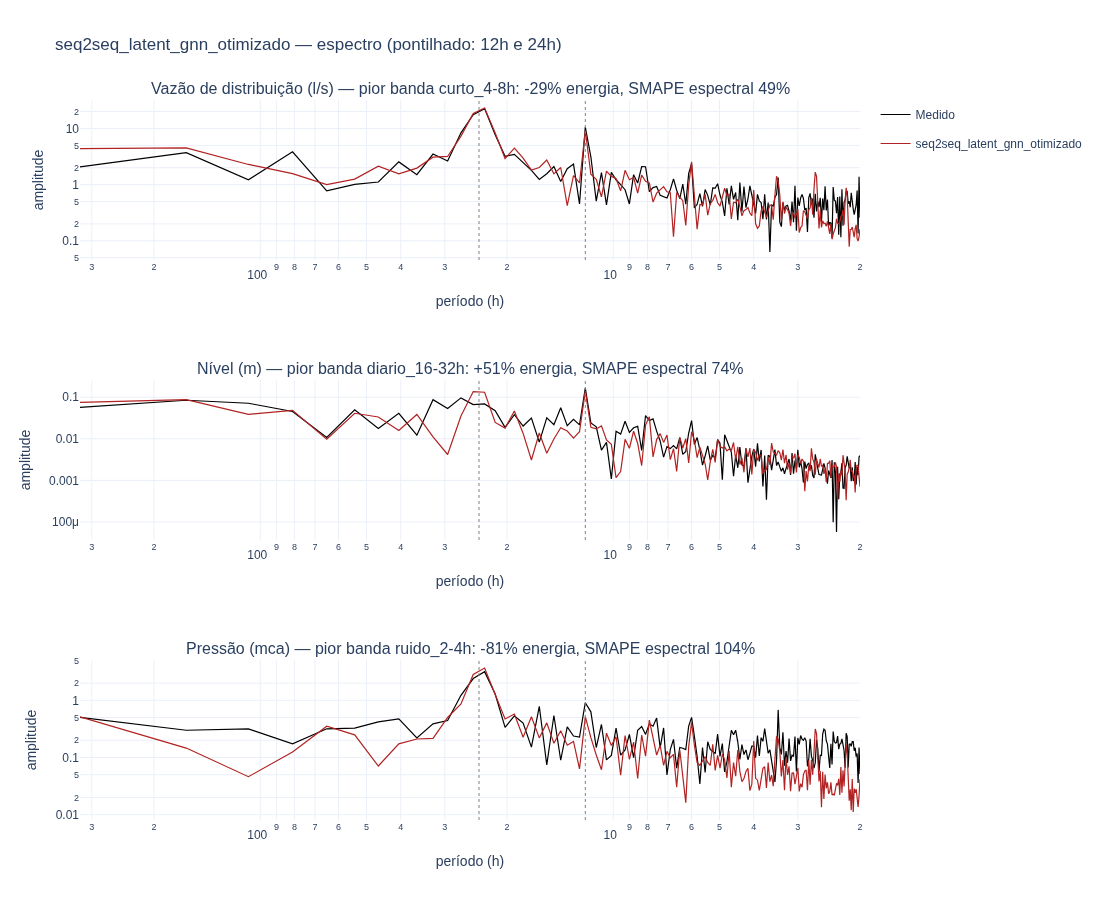

In [10]:
show_artifact("seq2seq_latent_gnn_otimizado", "espectro.png")

Baseline do mesmo modelo, para comparar lado a lado.

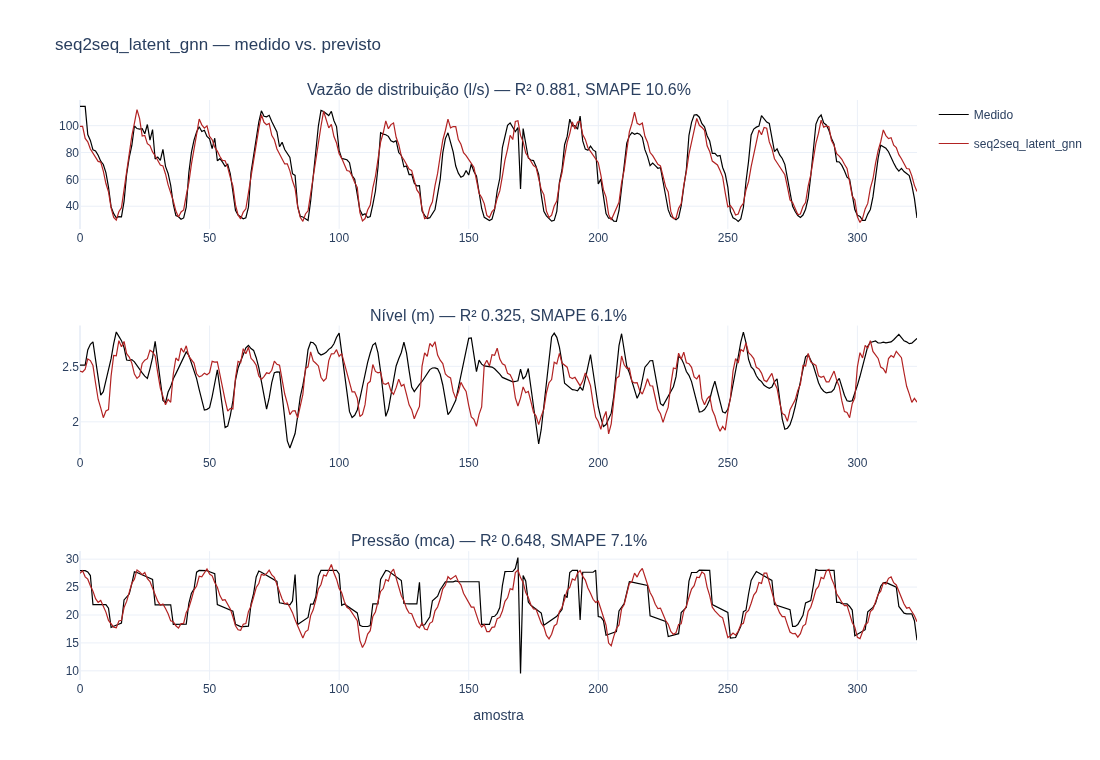

In [11]:
show_artifact("seq2seq_latent_gnn", "serie.png")

Repita `show_artifact("<modelo>[_otimizado]", ...)` para `mpnn`, `sgn` e `stemgnn`.